<a href="https://colab.research.google.com/github/rajat0304/IIITD/blob/Model/NDVI_ENGINE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!unzip -q archive_ms.zip -d eurosat_ms
!find eurosat_ms -maxdepth 3 -type d | head

unzip:  cannot find or open archive_ms.zip, archive_ms.zip.zip or archive_ms.zip.ZIP.
find: ‘eurosat_ms’: No such file or directory


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("nataliamorenomontoya/eurosat-msi")

print("Path to dataset files:", path)

100%|██████████| 1.93G/1.93G [00:27<00:00, 75.6MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/nataliamorenomontoya/eurosat-msi/versions/1


In [ ]:
import os
print(path)
!find "{path}" -maxdepth 3 -type d | head -30
!find "{path}" -type f | head -10

/root/.cache/kagglehub/datasets/nataliamorenomontoya/eurosat-msi/versions/1
/root/.cache/kagglehub/datasets/nataliamorenomontoya/eurosat-msi/versions/1
/root/.cache/kagglehub/datasets/nataliamorenomontoya/eurosat-msi/versions/1/EuroSAT_MS
/root/.cache/kagglehub/datasets/nataliamorenomontoya/eurosat-msi/versions/1/EuroSAT_MS/Residential
/root/.cache/kagglehub/datasets/nataliamorenomontoya/eurosat-msi/versions/1/EuroSAT_MS/River
/root/.cache/kagglehub/datasets/nataliamorenomontoya/eurosat-msi/versions/1/EuroSAT_MS/Highway
/root/.cache/kagglehub/datasets/nataliamorenomontoya/eurosat-msi/versions/1/EuroSAT_MS/HerbaceousVegetation
/root/.cache/kagglehub/datasets/nataliamorenomontoya/eurosat-msi/versions/1/EuroSAT_MS/SeaLake
/root/.cache/kagglehub/datasets/nataliamorenomontoya/eurosat-msi/versions/1/EuroSAT_MS/Industrial
/root/.cache/kagglehub/datasets/nataliamorenomontoya/eurosat-msi/versions/1/EuroSAT_MS/Forest
/root/.cache/kagglehub/datasets/nataliamorenomontoya/eurosat-msi/versions/1/Eur

In [ ]:
!pip install -q rasterio
import rasterio, glob

files = glob.glob(f"{path}/**/*.tif*", recursive=True)
print(len(files))
print(files[:3])

with rasterio.open(files[0]) as src:
    print("bands:", src.count)
    print("size:", src.width, "x", src.height)
    print("dtype:", src.dtypes[0])

27000
['/root/.cache/kagglehub/datasets/nataliamorenomontoya/eurosat-msi/versions/1/EuroSAT_MS/Residential/Residential_2814.tif', '/root/.cache/kagglehub/datasets/nataliamorenomontoya/eurosat-msi/versions/1/EuroSAT_MS/Residential/Residential_1276.tif', '/root/.cache/kagglehub/datasets/nataliamorenomontoya/eurosat-msi/versions/1/EuroSAT_MS/Residential/Residential_516.tif']
bands: 13
size: 64 x 64
dtype: uint16


In [ ]:
import rasterio, numpy as np, glob, os

ms_root = f"{path}/EuroSAT_MS"

def ndvi_from_tif(p):
    with rasterio.open(p) as src:
        red = src.read(4).astype("float32")   # B04
        nir = src.read(8).astype("float32")   # B08
    return (nir - red) / (nir + red + 1e-6)

for c in sorted(os.listdir(ms_root)):
    fs = sorted(glob.glob(f"{ms_root}/{c}/*.tif"))[:50]
    m = np.mean([ndvi_from_tif(f).mean() for f in fs])
    print(f"{c:22s} mean NDVI = {m:.2f}")

AnnualCrop             mean NDVI = 0.36
Forest                 mean NDVI = 0.71
HerbaceousVegetation   mean NDVI = 0.38
Highway                mean NDVI = 0.46
Industrial             mean NDVI = 0.24
Pasture                mean NDVI = 0.66
PermanentCrop          mean NDVI = 0.41
Residential            mean NDVI = 0.36
River                  mean NDVI = 0.34
SeaLake                mean NDVI = -0.23


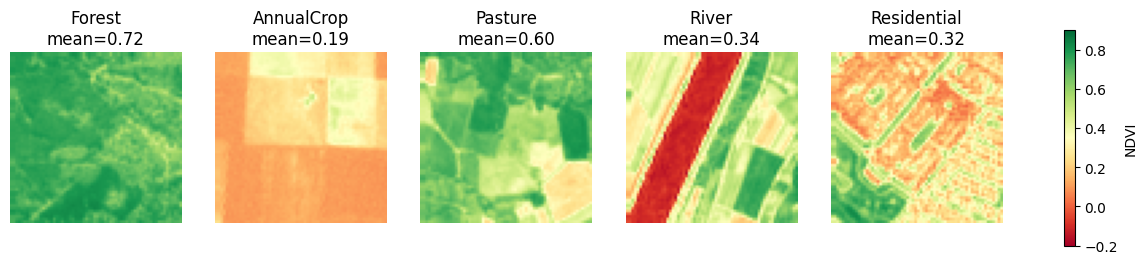

In [ ]:
import matplotlib.pyplot as plt

classes = ["Forest", "AnnualCrop", "Pasture", "River", "Residential"]
fig, ax = plt.subplots(1, len(classes), figsize=(16, 3.5))
for a, c in zip(ax, classes):
    f = sorted(glob.glob(f"{ms_root}/{c}/*.tif"))[0]
    nd = ndvi_from_tif(f)
    im = a.imshow(nd, cmap="RdYlGn", vmin=-0.2, vmax=0.9)
    a.set_title(f"{c}\nmean={nd.mean():.2f}"); a.axis("off")
fig.colorbar(im, ax=ax, shrink=0.8, label="NDVI")
plt.savefig("ndvi_samples.png", dpi=150, bbox_inches="tight")
plt.show()

config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  110MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  110MB            

model.safetensors: downloading bytes:           |  0.00B            

preprocessor_config.json:   0%|          | 0.00/240 [00:00<?, ?B/s]

Using Colab cache for faster access to the 'eurosat-msi' dataset.
['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Land cover tile accuracy: 98.4%
Farmland tiles: 40/64
Avg farmland NDVI: 0.45 -> Healthy


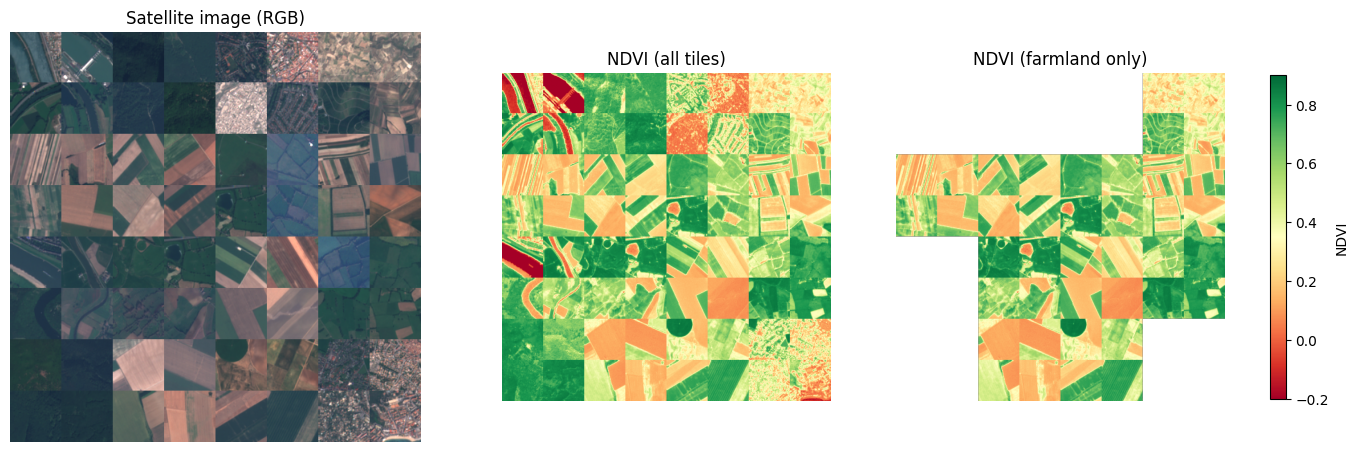

In [ ]:
!pip install -q rasterio kagglehub transformers

import os, glob, random
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from PIL import Image
import kagglehub
from transformers import pipeline

# 1. Model (agar reset ho gaya ho toh dobara load)
clf = pipeline("image-classification",
               model="nielsr/swin-tiny-patch4-window7-224-finetuned-eurosat")

# 2. Dataset (cache mein ho toh turant, warna dobara download)
path = kagglehub.dataset_download("nataliamorenomontoya/eurosat-msi")
ms_root = f"{path}/EuroSAT_MS"
print(sorted(os.listdir(ms_root)))

# 3. Ek tif se RGB aur NDVI dono
def read_tile(p):
    with rasterio.open(p) as src:
        b = src.read().astype("float32")        # (13, 64, 64)
    rgb = np.stack([b[3], b[2], b[1]], -1)      # B04, B03, B02
    rgb = (np.clip(rgb / 3000.0, 0, 1) * 255).astype("uint8")
    ndvi = (b[7] - b[3]) / (b[7] + b[3] + 1e-6) # (B08 - B04) / (B08 + B04)
    return Image.fromarray(rgb), ndvi

# 4. Mosaic
random.seed(7)
use = ["AnnualCrop", "Forest", "River", "Residential", "Pasture", "PermanentCrop"]
rows, cols, T = 8, 8, 64

grid = [[None]*cols for _ in range(rows)]
for bi in range(0, rows, 2):
    for bj in range(0, cols, 2):
        c = random.choice(use)
        for di in range(2):
            for dj in range(2):
                grid[bi+di][bj+dj] = c

mosaic = Image.new("RGB", (cols*T, rows*T))
ndvi_map = np.zeros((rows*T, cols*T), dtype="float32")
truth = []
for i in range(rows):
    for j in range(cols):
        c = grid[i][j]
        f = random.choice(glob.glob(f"{ms_root}/{c}/*.tif"))
        rgb_img, nd = read_tile(f)
        mosaic.paste(rgb_img, (j*T, i*T))
        ndvi_map[i*T:(i+1)*T, j*T:(j+1)*T] = nd
        truth.append(c)

# 5. Land cover prediction
tiles = [mosaic.crop((j*T, i*T, (j+1)*T, (i+1)*T)) for i in range(rows) for j in range(cols)]
labels = [p[0]["label"] for p in clf(tiles, batch_size=32)]
acc = np.mean([a == b for a, b in zip(labels, truth)])
print(f"Land cover tile accuracy: {acc*100:.1f}%")

# 6. Sirf farmland ka NDVI
farm = {"AnnualCrop", "PermanentCrop", "Pasture", "HerbaceousVegetation"}
masked = ndvi_map.copy()
farm_vals = []
for idx, lab in enumerate(labels):
    i, j = divmod(idx, cols)
    sl = (slice(i*T, (i+1)*T), slice(j*T, (j+1)*T))
    if lab in farm:
        farm_vals.append(ndvi_map[sl].mean())
    else:
        masked[sl] = np.nan

def health(m):
    if m < 0.2: return "Bare / Stressed"
    if m < 0.4: return "Sparse / Moderate"
    if m < 0.6: return "Healthy"
    return "Very healthy"

fm = float(np.mean(farm_vals))
print(f"Farmland tiles: {len(farm_vals)}/{len(labels)}")
print(f"Avg farmland NDVI: {fm:.2f} -> {health(fm)}")

# 7. Plot
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(mosaic); ax[0].set_title("Satellite image (RGB)")
ax[1].imshow(ndvi_map, cmap="RdYlGn", vmin=-0.2, vmax=0.9); ax[1].set_title("NDVI (all tiles)")
im = ax[2].imshow(masked, cmap="RdYlGn", vmin=-0.2, vmax=0.9); ax[2].set_title("NDVI (farmland only)")
fig.colorbar(im, ax=ax[1:], shrink=0.7, label="NDVI")
for a in ax: a.axis("off")
plt.savefig("combined_map.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
import pickle, torch, transformers, sys

clf.model.to("cpu").eval()

with open("eurosat_clf.pkl", "wb") as f:
    pickle.dump(clf, f)

print("python:", sys.version.split()[0])
print("torch:", torch.__version__)
print("transformers:", transformers.__version__)

from google.colab import files
files.download("eurosat_clf.pkl")

python: 3.13.16
torch: 2.11.0+cpu
transformers: 5.18.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>